
# Outlier detection with Local Outlier Factor (LOF)

The Local Outlier Factor (LOF) algorithm is an unsupervised anomaly detection
method which computes the local density deviation of a given data point with
respect to its neighbors. It considers as outliers the samples that have a
substantially lower density than their neighbors. This example shows how to use
LOF for outlier detection which is the default use case of this estimator in
scikit-learn. Note that when LOF is used for outlier detection it has no
`predict`, `decision_function` and `score_samples` methods. See the `User
Guide <outlier_detection>` for details on the difference between outlier
detection and novelty detection and how to use LOF for novelty detection.

The number of neighbors considered (parameter `n_neighbors`) is typically set 1)
greater than the minimum number of samples a cluster has to contain, so that
other samples can be local outliers relative to this cluster, and 2) smaller
than the maximum number of close by samples that can potentially be local
outliers. In practice, such information is generally not available, and taking
`n_neighbors=20` appears to work well in general.


In [ ]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

## Generate data with outliers



In [ ]:
import numpy as np

np.random.seed(42)

X_inliers = 0.3 * np.random.randn(100, 2)# datos normales centrados en el origen
X_inliers = np.r_[X_inliers + 2, X_inliers - 2]# datos normales desplazados a (2,2) y (-2,-2)
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))# datos uniformes en el rango [-4,4] en ambas dimensiones
X = np.r_[X_inliers, X_outliers]# combinar inliers y outliers

n_outliers = len(X_outliers)# número de outliers
ground_truth = np.ones(len(X), dtype=int)#ground_truth es un array de unos de tamaño len(X), sirve para indicar que todos los puntos son inliers
#np.ones crea un array de unos(1) de tamaño len(X)
ground_truth[-n_outliers:] = -1# los últimos n_outliers puntos son outliers, se indica con -1

## Fit the model for outlier detection (default)

Use `fit_predict` to compute the predicted labels of the training samples
(when LOF is used for outlier detection, the estimator has no `predict`,
`decision_function` and `score_samples` methods).



In [2]:
from sklearn.neighbors import LocalOutlierFactor# importamos la clase LocalOutlierFactor del módulo neighbors de sklearn, 
# sirve para detectar valores atípicos en un conjunto de datos utilizando la densidad local

#local outlier factor es un algoritmo de detección de anomalías basado en la densidad local de los datos
clf = LocalOutlierFactor(n_neighbors=20, contamination=0.1)# contamination es la proporción de outliers en los datos
y_pred = clf.fit_predict(X)# predicciones del modelo para cada punto, -1 para outlier y 1 para inlier
n_errors = (y_pred != ground_truth).sum()# número de errores de predicción
X_scores = clf.negative_outlier_factor_# puntuaciones de outlier negativas, cuanto más bajo el valor, más probable es que sea un outlier

## Plot results



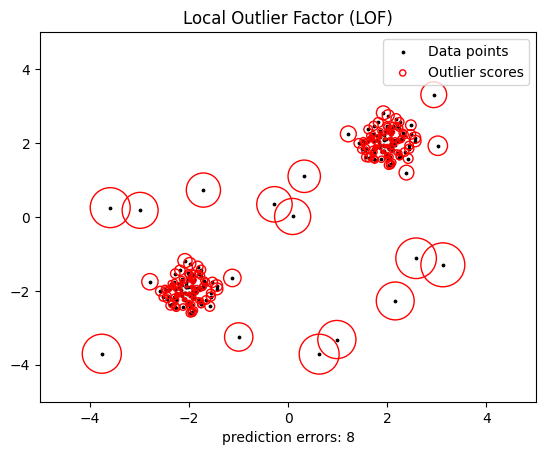

In [3]:
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerPathCollection


def update_legend_marker_size(handle, orig):#funcion que actualiza el tamaño del marcador de la leyenda
    "Customize size of the legend marker"
    handle.update_from(orig)
    handle.set_sizes([20])


plt.scatter(X[:, 0], X[:, 1], color="k", s=3.0, label="Data points")# dibujar los puntos de datos
# plot circles with radius proportional to the outlier scores
radius = (X_scores.max() - X_scores) / (X_scores.max() - X_scores.min())# radius es un array que contiene los radios de los círculos que se van a dibujar,
# proporcionales a las puntuaciones de outlier
scatter = plt.scatter(
    X[:, 0],
    X[:, 1],
    s=1000 * radius,
    edgecolors="r",
    facecolors="none",
    label="Outlier scores",
)
plt.axis("tight")
plt.xlim((-5, 5))
plt.ylim((-5, 5))
plt.xlabel("prediction errors: %d" % (n_errors))
plt.legend(
    handler_map={scatter: HandlerPathCollection(update_func=update_legend_marker_size)}
)
plt.title("Local Outlier Factor (LOF)")
plt.show()